# Lab 6 — Odometry: model vs real robot

**Course:** CS413 Robotics · **Robot:** TRIK, differential drive · **Trajectory:** the digits **"47"** (last two digits of the student ID)

The same program (`trajectory_sim.qrs` = `trajectory_real.qrs`) drove "47" in the TRIK Studio 2D simulator and on the real robot, logging its odometry `x, y, time`. The two logs are compared here, and the real robot's odometry is checked against a tape measurement of where it actually stopped.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:                                   # in Colab: upload odometry_data_sim.txt and odometry_data_real.txt
    from google.colab import files
    files.upload()
except ImportError:
    pass

A, GAP = 0.30, 0.20                    # stroke length and gap between the digits, m
plan = np.array([(0, 0), (0, -A), (A, -A), (A, 0), (A, -2 * A), (A, 0),
                 (A + GAP, 0), (2 * A + GAP, 0), (2 * A + GAP, -2 * A)])

## 1. The two logs

Format required by the lab: one line per sample, no header, `x,y,time` in metres, metres and milliseconds.

In [2]:
def load(name):
    if not os.path.exists(name):
        return None
    x, y, t = np.loadtxt(name, delimiter=",", unpack=True)
    return {"x": x, "y": y, "t": t - t[0]}

sim = load("odometry_data_sim.txt")
real = load("odometry_data_real.txt")
logs = {"model (simulator)": sim, "real robot": real}

rows = []
for name, d in logs.items():
    if d is None:
        rows.append({"run": name, "samples": "not recorded yet"})
        continue
    rows.append({"run": name, "samples": len(d["x"]), "duration [s]": round(d["t"][-1] / 1000, 1),
                 "mean period [ms]": round(np.mean(np.diff(d["t"])), 1),
                 "path length [m]": round(np.sum(np.hypot(np.diff(d["x"]), np.diff(d["y"]))), 3),
                 "end x [m]": round(d["x"][-1], 3), "end y [m]": round(d["y"][-1], 3)})
pd.DataFrame(rows).set_index("run")

,samples,duration [s],mean period [ms],path length [m],end x [m],end y [m]
run,,,,,,
model (simulator),1398,43.0,30.8,3.227,0.800,-0.598
real robot,993,49.8,50.2,3.574,0.805,-0.601


## 2. Trajectories: model vs real

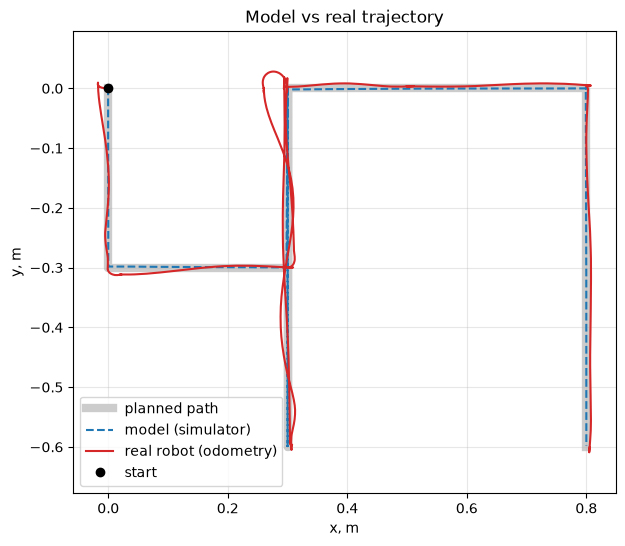

In [3]:
plt.figure(figsize=(7, 6))
plt.plot(plan[:, 0], plan[:, 1], color="0.8", lw=6, label="planned path", zorder=1)
if sim is not None:
    plt.plot(sim["x"], sim["y"], "--", color="#1f77b4", label="model (simulator)")
if real is not None:
    plt.plot(real["x"], real["y"], color="#d62728", label="real robot (odometry)")
plt.plot(0, 0, "ko", label="start")
plt.axis("equal"); plt.grid(True, alpha=0.3); plt.legend()
plt.xlabel("x, m"); plt.ylabel("y, m"); plt.title("Model vs real trajectory")
plt.show()

## 3. Position error over time

The simulator log is resampled onto the real robot's time stamps, and the distance between the two positions is computed at every moment.

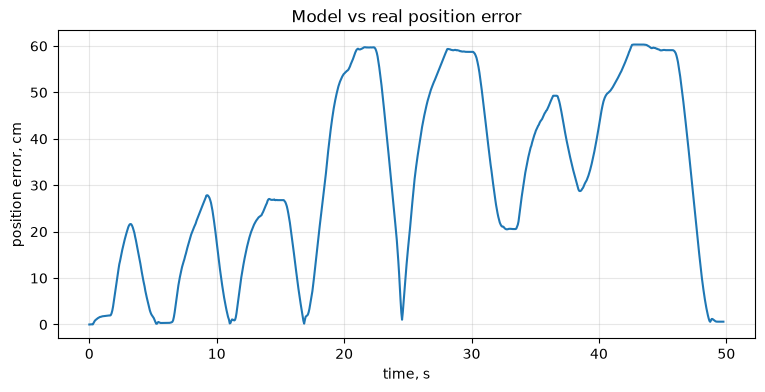

Final odometry error (sim vs real): 0.6 cm
Max error: 60.3 cm


In [4]:
if sim is None or real is None:
    print("needs both logs - run the program on the real robot first")
else:
    xs_i = np.interp(real["t"], sim["t"], sim["x"])
    ys_i = np.interp(real["t"], sim["t"], sim["y"])
    err = np.hypot(real["x"] - xs_i, real["y"] - ys_i)

    plt.figure(figsize=(9, 4))
    plt.plot(real["t"] / 1000, err * 100)
    plt.xlabel("time, s"); plt.ylabel("position error, cm"); plt.grid(True, alpha=0.3)
    plt.title("Model vs real position error")
    plt.show()

    print(f"Final odometry error (sim vs real): {err[-1]*100:.1f} cm")
    print(f"Max error: {err.max()*100:.1f} cm")